# Part 1 - Recurrent Neural Networks

## Author Identification Using Writing Style

**Student:** Boitumelo Malinga  
**Student Number:** ST10107491  
**Module:** PDAN8412/w

## Importing Libraries

In this step, I imported the libraries required for data handling, Spark analysis, visualisation, text preparation, model development and model evaluation. I also set a random seed to make the results reproducible.

In [1]:
import os
import re
import json
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from pyspark.sql import SparkSession, functions as F, types as T

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 120

def display_table(data, title, formats=None, hide_index=True):
    # Consistent report-ready styling was applied to notebook tables.
    styled_table = (
        data.style
        .set_caption(title)
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("background-color", "#163A5F"),
                    ("color", "white"),
                    ("font-size", "15px"),
                    ("font-weight", "bold"),
                    ("padding", "10px"),
                    ("text-align", "left")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", "#2F6690"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("padding", "8px 12px"),
                    ("border", "1px solid #D9E2EC"),
                    ("text-align", "center")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "8px 12px"),
                    ("border", "1px solid #D9E2EC"),
                    ("text-align", "center")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [("background-color", "#EDF4FA")]
            },
            {
                "selector": "tbody tr:hover",
                "props": [("background-color", "#D7E9F7")]
            }
        ])
        .set_properties(**{"font-family": "Arial, sans-serif", "font-size": "13px"})
    )

    if formats:
        styled_table = styled_table.format(formats)
    if hide_index:
        styled_table = styled_table.hide(axis="index")

    display(styled_table)

/opt/anaconda3/envs/pdan8412/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Loading the Dataset

I used the PAN2020 Fanfiction Author-Fandom Document dataset. The complete dataset is large, so I streamed a sample of at least 12,000 valid documents and saved it locally. This exceeds the required minimum of 10,000 records while keeping the analysis manageable on my computer.

In [2]:
DATASET_ID = "peterkirby/pan2020_dict_author_fandom_doc"
MIN_RECORDS = 12_000
MAX_RECORDS = 30_000
MIN_DOCUMENTS_PER_AUTHOR = 3
NUMBER_OF_AUTHORS = 5
MAX_TEXT_CHARACTERS = 25_000

MAC_CACHE_FOLDER = (
    Path.home()
    / "Documents"
    / "PDAN8412_Part1"
    / "pdan8412_pan_cache"
)

DATA_FOLDER = (
    MAC_CACHE_FOLDER
    if MAC_CACHE_FOLDER.exists()
    else Path("pdan8412_pan_cache").resolve()
)
DATA_FOLDER.mkdir(exist_ok=True)
DATA_FILE = DATA_FOLDER / "pan2020_source_sample.jsonl"

def download_dataset_sample(file_path=DATA_FILE):
    if file_path.exists():
        print("The saved dataset sample will be used.")
        return

    dataset_stream = load_dataset(
        DATASET_ID,
        "default",
        split="train",
        streaming=True
    )

    author_counts = Counter()
    records_saved = 0

    with file_path.open("w", encoding="utf-8") as output_file:
        for document_id, row in enumerate(dataset_stream):
            text = row.get("text")
            author = row.get("author_str")

            if text is None or author is None or not str(text).strip():
                continue

            record = {
                "document_id": int(document_id),
                "author": str(author),
                "author_int": int(row.get("author_int", -1)),
                "fandom": str(row.get("fandom_str", "Unknown")),
                "fandom_int": int(row.get("fandom_int", -1)),
                "text": str(text)[:MAX_TEXT_CHARACTERS]
            }

            output_file.write(json.dumps(record, ensure_ascii=False) + "\n")
            author_counts[record["author"]] += 1
            records_saved += 1

            suitable_authors = sum(
                count >= MIN_DOCUMENTS_PER_AUTHOR
                for count in author_counts.values()
            )

            if records_saved >= MIN_RECORDS and suitable_authors >= NUMBER_OF_AUTHORS:
                break

            if records_saved >= MAX_RECORDS:
                break

    if records_saved < 10_000:
        raise ValueError("Fewer than 10,000 valid records were downloaded.")

    print(f"Records saved: {records_saved:,}")
    print(f"Dataset location: {file_path.resolve()}")

download_dataset_sample()

The saved dataset sample will be used.


## Creating the Spark DataFrame

I created a local Spark session and loaded the saved records into a Spark DataFrame. Spark was used to examine and prepare the large source dataset before the neural network was trained.

In [3]:
spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("PDAN8412 Author Identification")
    .config("spark.driver.memory", "2g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

dataset_schema = T.StructType([
    T.StructField("document_id", T.LongType(), False),
    T.StructField("author", T.StringType(), True),
    T.StructField("author_int", T.LongType(), True),
    T.StructField("fandom", T.StringType(), True),
    T.StructField("fandom_int", T.LongType(), True),
    T.StructField("text", T.StringType(), True)
])

df = spark.read.schema(dataset_schema).json(str(DATA_FILE.resolve())).cache()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/06 11:44:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### Spark DataFrame Confirmation

The Spark version and record count confirmed that the local processing environment and the required dataset sample were available.

In [4]:
print("Spark version:", spark.version)
print("Number of records:", f"{df.count():,}")

Spark version: 3.5.9


[Stage 0:>                                                          (0 + 2) / 2]

Number of records: 12,000


### Dataset Preview

The first five records were displayed to confirm the structure and content of the loaded dataset.

In [5]:
df.show(5, truncate=70)

+-----------+-------+----------+---------------------------------+----------+----------------------------------------------------------------------+
|document_id| author|author_int|                           fandom|fandom_int|                                                                  text|
+-----------+-------+----------+---------------------------------+----------+----------------------------------------------------------------------+
|          0|4623254|    152105|Infernal Devices, Cassandra Clare|       498|Growing up with a brother, you always did things together. Gabriel ...|
|          1|1109813|      9734|                  Life With Derek|       596|been spending more time with Derek, but that didn't mean she wanted...|
|          2|2414395|     78362|                       True Blood|      1050|She was amazed by how quickly he could switch modes from inhumane a...|
|          3|  42173|    136363|                    Fushigi Yuugi|       368|"We would be honored to serve

## Understanding the Dataset

I examined the schema to understand the variables and their data types. The text field contained the writing sample, while the author field represented the target class that the model would predict.

In [6]:
df.printSchema()

root
 |-- document_id: long (nullable = true)
 |-- author: string (nullable = true)
 |-- author_int: long (nullable = true)
 |-- fandom: string (nullable = true)
 |-- fandom_int: long (nullable = true)
 |-- text: string (nullable = true)



### Dataset Overview Table

The dataset overview summarised the number of records, authors and fandoms in the Spark DataFrame.

In [7]:
dataset_summary_row = df.agg(
    F.count("*").alias("Records"),
    F.countDistinct("author").alias("Unique Authors"),
    F.countDistinct("fandom").alias("Unique Fandoms")
).first()

dataset_summary = pd.DataFrame([dataset_summary_row.asDict()])

In [8]:
display_table(dataset_summary, "Dataset Overview", {"Records": "{:,.0f}", "Unique Authors": "{:,.0f}", "Unique Fandoms": "{:,.0f}"})

Records,Unique Authors,Unique Fandoms
"12,000","7,235",980


## Checking for Missing Values

I checked the dataset for missing or blank values. Missing author labels or text could not be used to train an author identification model.

In [9]:
missing_values_row = df.select([
    F.sum(
        F.when(F.col(column).isNull() | (F.trim(F.col(column).cast("string")) == ""), 1)
        .otherwise(0)
    ).alias(column)
    for column in df.columns
]).first()

missing_values = pd.DataFrame([missing_values_row.asDict()])
missing_table = missing_values.T.reset_index()
missing_table.columns = ["Field", "Missing Values"]

In [10]:
display_table(missing_table, "Missing-Value Summary")

Field,Missing Values
document_id,0
author,0
author_int,0
fandom,0
fandom_int,0
text,0


## Checking for Duplicate Records

I checked for repeated author and text combinations. Duplicate writing samples could give the model repeated information and make its performance appear stronger than it was.

In [11]:
duplicate_value = (
    df.groupBy("author", "text")
    .count()
    .filter(F.col("count") > 1)
    .agg(F.sum(F.col("count") - 1).alias("Duplicate Records"))
    .first()[0]
)

duplicate_records = pd.DataFrame({
    "Duplicate Records": [0 if duplicate_value is None else duplicate_value]
})

In [12]:
display_table(duplicate_records, "Duplicate-Record Summary")

Duplicate Records
0


## Cleaning the Dataset

I removed records with missing author labels or text, trimmed unnecessary spaces and removed exact duplicates. I then created character, word and sentence counts for the exploratory analysis.

In [13]:
df_clean = (
    df
    .filter(F.col("author").isNotNull() & (F.trim("author") != ""))
    .filter(F.col("text").isNotNull() & (F.trim("text") != ""))
    .withColumn("text", F.trim("text"))
    .dropDuplicates(["author", "text"])
    .withColumn("character_count", F.length("text"))
    .withColumn("word_count", F.size(F.split(F.trim("text"), r"\s+")))
    .withColumn("sentence_count", F.size(F.split("text", r"[.!?]+")))
    .cache()
)

print("Records before cleaning:", f"{df.count():,}")
print("Records after cleaning:", f"{df_clean.count():,}")

Records before cleaning: 12,000


[Stage 25:=============================>                            (2 + 2) / 4]

Records after cleaning: 11,999


### Data Quality Findings

The Spark analysis included 12,000 documents from 7,235 authors and 980 fandoms. No missing values were identified in the required fields, and no repeated author-text combinations were found. After applying all cleaning conditions, 11,999 records remained available for analysis. The dataset was therefore largely complete and required minimal cleaning.

## Descriptive Statistics

I calculated descriptive statistics for the document lengths. This helped me determine whether the writing samples contained enough words to be divided into consistent sequences for the LSTM model.

In [14]:
statistics_rows = df_clean.select(
    "character_count",
    "word_count",
    "sentence_count"
).summary().collect()

descriptive_statistics = pd.DataFrame([row.asDict() for row in statistics_rows])

In [15]:
display_table(descriptive_statistics, "Document-Length Descriptive Statistics")

summary,character_count,word_count,sentence_count
count,11999,11999,11999
mean,21374.755729644137,3911.517709809151,370.7543961996833
stddev,410.50584518183683,157.8742412330026,102.6245214322576
min,20709,2288,25
25%,21197,3811,301
50%,21289,3898,362
75%,21432,3997,433
max,25000,4974,855


## Data Visualisation

I used visualisations to examine document length, author representation and fandom representation. These patterns guided the selection and preparation of the modelling data.

### Distribution of Document Lengths

I used a histogram to examine the distribution of document word counts. The values were capped at the 99th percentile in the graph so that extremely long documents did not hide the main distribution.

In [16]:
clean_count = df_clean.count()
plot_fraction = min(1.0, 10_000 / clean_count)

length_data = (
    df_clean.select("word_count")
    .sample(False, plot_fraction, seed=SEED)
    .limit(10_000)
    .collect()
)

length_data = pd.DataFrame([row.asDict() for row in length_data])

word_limit = int(length_data["word_count"].quantile(0.99))

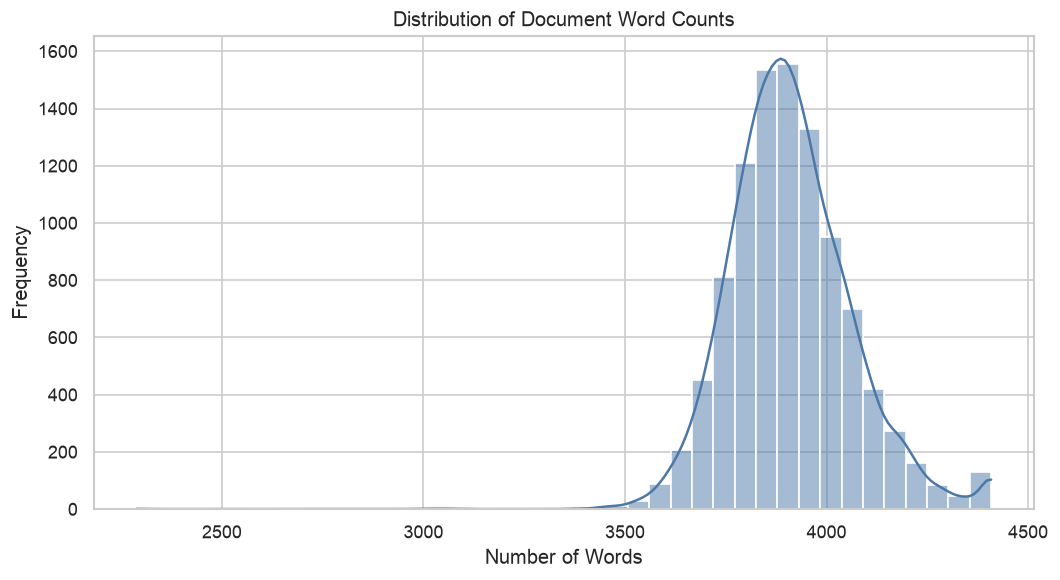

In [17]:
plt.figure(figsize=(9, 5))
sns.histplot(
    length_data["word_count"].clip(upper=word_limit),
    bins=40,
    kde=True,
    color="#4C78A8"
)
plt.title("Distribution of Document Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

The document lengths were concentrated around approximately 3,900 words, with most observations falling between roughly 3,700 and 4,200 words. The documents were therefore sufficiently long to create multiple 180-word sequences for LSTM training. The distribution also showed a small number of longer documents, but these did not dominate the main pattern.

### Authors with the Most Documents

I compared the authors with the highest number of documents. This showed the level of class imbalance and identified authors with enough source material for model development.

In [18]:
author_distribution = (
    df_clean.groupBy("author")
    .agg(
        F.count("*").alias("document_count"),
        F.countDistinct("fandom").alias("fandom_count"),
        F.avg("word_count").alias("average_words")
    )
    .orderBy(F.desc("document_count"), F.desc("fandom_count"))
)

top_author_rows = author_distribution.limit(15).collect()
top_authors = pd.DataFrame([row.asDict() for row in top_author_rows])

In [19]:
display_table(
    top_authors,
    "Top 15 Authors by Source-Document Count",
    {"average_words": "{:,.2f}"}
)

author,document_count,fandom_count,average_words
443979,30,6,"3,995.13"
131294,29,6,"3,931.07"
5609007,28,6,"3,934.11"
1265193,28,6,"3,895.04"
5419510,28,6,"4,006.21"
1370220,27,6,"3,985.52"
4236270,27,6,"3,950.52"
5649902,26,6,"4,200.42"
1373442,26,6,"3,955.88"
2313539,25,6,"3,947.96"


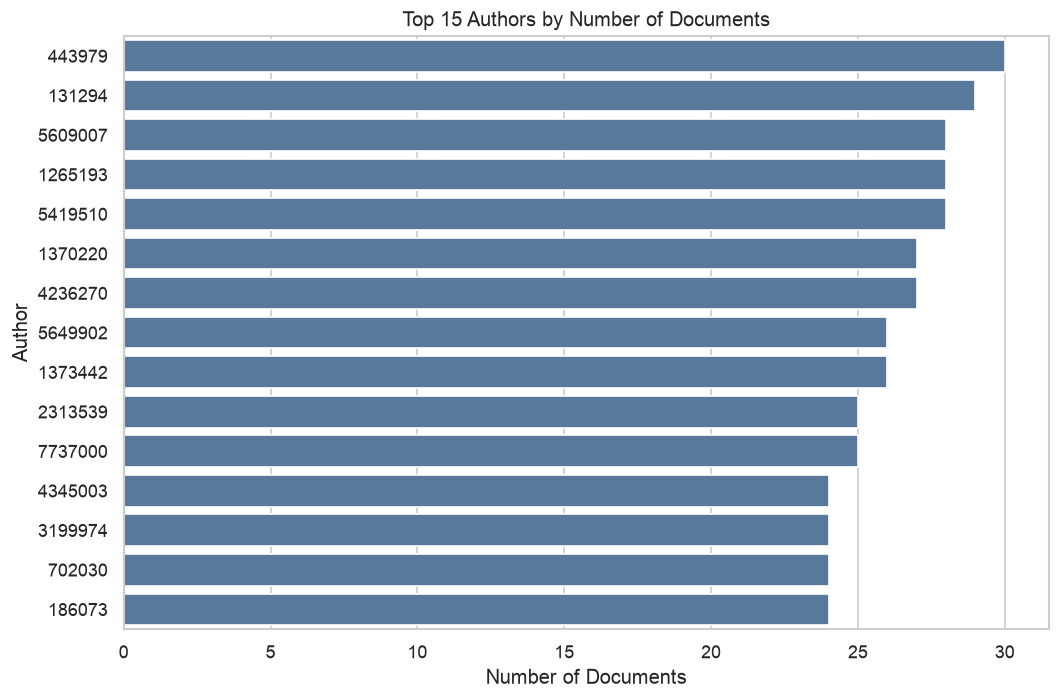

In [20]:
plt.figure(figsize=(9, 6))
sns.barplot(
    data=top_authors,
    x="document_count",
    y="author",
    color="#4C78A8"
)
plt.title("Top 15 Authors by Number of Documents")
plt.xlabel("Number of Documents")
plt.ylabel("Author")
plt.tight_layout()
plt.show()

The most represented authors contained between 24 and 30 documents. Author 443979 had the highest representation with 30 documents, followed by author 131294 with 29. The differences between the leading authors are relatively small, but balancing was still applied before training so that every selected author contributed the same number of text samples.

### Fandom Distribution

I examined the most common fandoms because the model could learn topic-specific words instead of writing style. Fandom is therefore an important possible source of bias in this dataset.

In [21]:
top_fandom_rows = (
    df_clean.groupBy("fandom")
    .count()
    .orderBy(F.desc("count"))
    .limit(15)
    .collect()
)

top_fandoms = pd.DataFrame([row.asDict() for row in top_fandom_rows])

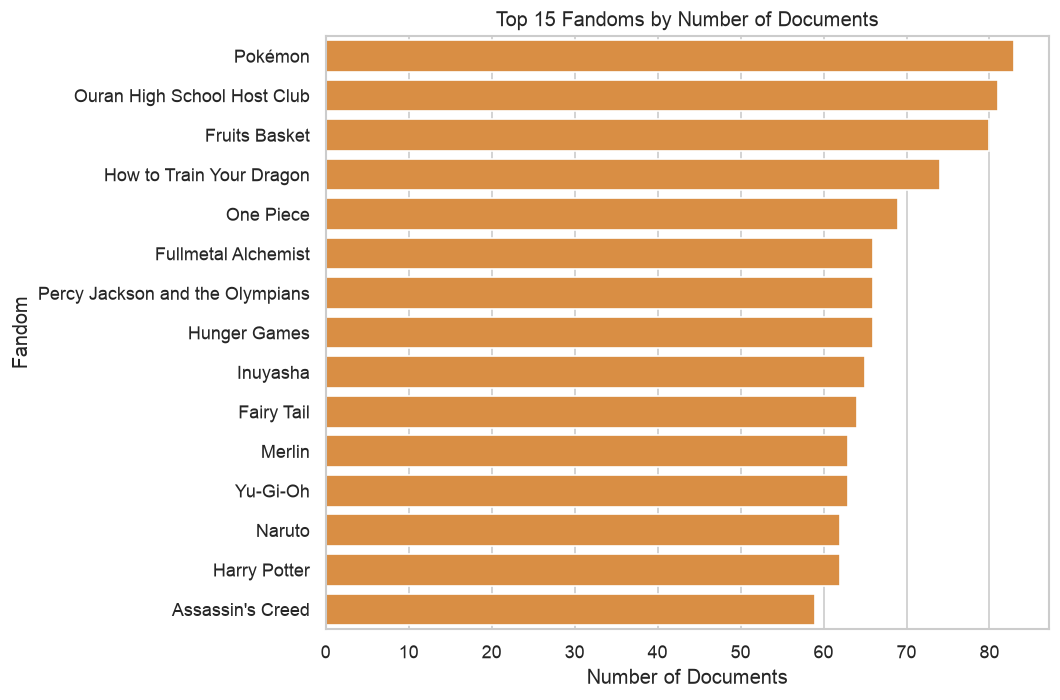

In [22]:
plt.figure(figsize=(9, 6))
sns.barplot(
    data=top_fandoms,
    x="count",
    y="fandom",
    color="#F28E2B"
)
plt.title("Top 15 Fandoms by Number of Documents")
plt.xlabel("Number of Documents")
plt.ylabel("Fandom")
plt.tight_layout()
plt.show()

The source documents covered a wide range of fandoms, including Pokémon, Ouran High School Host Club, Fruits Basket and How to Train Your Dragon. This confirmed that topic variation is present in the dataset. Fandom was excluded from the model features because the purpose of the model was to learn writing style rather than to recognise subjects, characters or fictional settings.

## Selecting Authors for the Model

I selected five authors with at least three documents, prioritising document count and fandom diversity. This created a manageable multiclass classification problem and allowed source documents to be separated across the training, validation and test sets.

In [23]:
selected_author_rows = (
    author_distribution
    .filter(F.col("document_count") >= MIN_DOCUMENTS_PER_AUTHOR)
    .limit(NUMBER_OF_AUTHORS)
    .collect()
)

selected_author_data = pd.DataFrame([
    row.asDict() for row in selected_author_rows
])

if len(selected_author_data) < NUMBER_OF_AUTHORS:
    raise ValueError(
        "The sample does not contain enough authors with three documents. "
        "A larger source sample is required."
    )

selected_authors = selected_author_data["author"].tolist()

In [24]:
display_table(
    selected_author_data,
    "Authors Selected for Model Development",
    {"average_words": "{:,.2f}"}
)

author,document_count,fandom_count,average_words
443979,30,6,"3,995.13"
131294,29,6,"3,931.07"
5609007,28,6,"3,934.11"
1265193,28,6,"3,895.04"
5419510,28,6,"4,006.21"


## Preparing the Text

I kept punctuation and common words because they could reflect an author's writing style. URLs and unnecessary spaces were removed. Long documents were then divided into non-overlapping samples of 180 words so that they could be processed consistently by the LSTM.

In [25]:
selected_document_rows = (
    df_clean
    .filter(F.col("author").isin(selected_authors))
    .select("document_id", "author", "fandom", "text")
    .collect()
)

selected_documents = pd.DataFrame([
    row.asDict() for row in selected_document_rows
])

CHUNK_SIZE = 180
MINIMUM_CHUNK_SIZE = 100
MAX_CHUNKS_PER_AUTHOR = 180

def clean_text(text):
    text = re.sub(r"https?://\S+|www\.\S+", " <URL> ", str(text))
    return re.sub(r"\s+", " ", text).strip()

def create_chunks(text):
    words = clean_text(text).split()
    chunks = []

    for start in range(0, len(words), CHUNK_SIZE):
        chunk = words[start:start + CHUNK_SIZE]
        if len(chunk) >= MINIMUM_CHUNK_SIZE:
            chunks.append(" ".join(chunk))

    return chunks

chunk_records = []

for row in selected_documents.itertuples(index=False):
    for chunk_number, text_chunk in enumerate(create_chunks(row.text)):
        chunk_records.append({
            "document_id": row.document_id,
            "chunk_id": f"{row.document_id}_{chunk_number}",
            "author": row.author,
            "fandom": row.fandom,
            "text": text_chunk,
            "word_count": len(text_chunk.split())
        })

chunks = pd.DataFrame(chunk_records)

chunk_preview = chunks[[
    "document_id", "chunk_id", "author", "fandom", "word_count"
]].head()

### Prepared Text Sample Preview

The preview confirmed that the selected documents had been divided into labelled text samples of a consistent size.

In [26]:
display_table(chunk_preview, "Prepared Text Sample Preview")

document_id,chunk_id,author,fandom,word_count
4656,4656_0,1265193,Fushigi Yuugi,180
4656,4656_1,1265193,Fushigi Yuugi,180
4656,4656_2,1265193,Fushigi Yuugi,180
4656,4656_3,1265193,Fushigi Yuugi,180
4656,4656_4,1265193,Fushigi Yuugi,180


## Balancing the Author Classes

I kept the same maximum number of text samples for each author. Samples were drawn across the available source documents so that a single long document did not dominate an author's class.

In [27]:
def sample_author_chunks(author_data):
    document_groups = [
        document.sample(frac=1, random_state=SEED).reset_index(drop=True)
        for _, document in author_data.groupby("document_id")
    ]

    selected_rows = []
    row_number = 0

    while len(selected_rows) < min(MAX_CHUNKS_PER_AUTHOR, len(author_data)):
        row_added = False

        for document in document_groups:
            if row_number < len(document) and len(selected_rows) < MAX_CHUNKS_PER_AUTHOR:
                selected_rows.append(document.iloc[row_number])
                row_added = True

        if not row_added:
            break

        row_number += 1

    return pd.DataFrame(selected_rows)

balanced_chunks = pd.concat(
    [sample_author_chunks(group) for _, group in chunks.groupby("author")],
    ignore_index=True
)

balanced_author_table = (
    balanced_chunks["author"].value_counts()
    .rename_axis("Author")
    .reset_index(name="Number of Text Samples")
)

In [28]:
display_table(balanced_author_table, "Balanced Author Classes")

Author,Number of Text Samples
1265193,180
131294,180
443979,180
5419510,180
5609007,180


In [29]:
class_distribution = balanced_chunks["author"].value_counts()

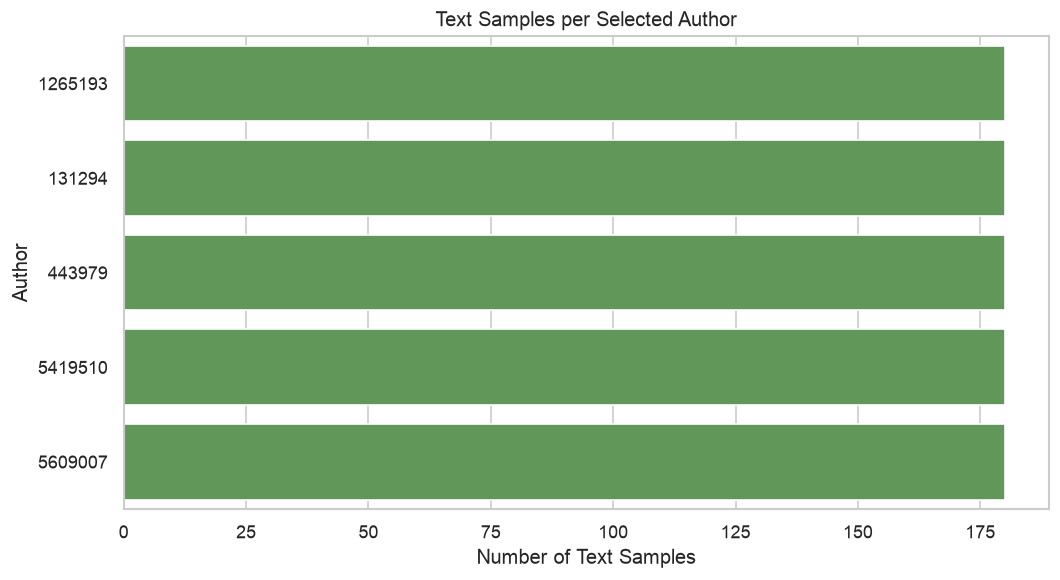

In [30]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x=class_distribution.values,
    y=class_distribution.index,
    color="#59A14F"
)
plt.title("Text Samples per Selected Author")
plt.xlabel("Number of Text Samples")
plt.ylabel("Author")
plt.tight_layout()
plt.show()

After text preparation and balancing, each of the five selected authors contributed 180 text samples. The final modelling dataset therefore contained 900 balanced samples. This prevented the model from favouring an author simply because that author had more training observations.

## Feature Selection

For this text classification problem, the writing sample was the main input feature and the author identifier was the target variable. I excluded the fandom variable from the model because it represented the subject of the document rather than the author's writing style. Including it could have caused the model to associate particular topics or character names with an author.

I preserved punctuation, common words and sentence structure because these could contain useful stylistic patterns. URLs and unnecessary spaces were removed because they did not provide reliable evidence of authorship.

The vocabulary was limited to the 20,000 most frequent training tokens to retain useful words while controlling model complexity. An out-of-vocabulary token was used for unseen or uncommon words. Each document was divided into sequences of 180 words, providing enough context for the LSTM while keeping the input size manageable. The final training vocabulary contained 8,211 unique tokens.

## Encoding the Author Labels

I converted the author identifiers into numerical class labels because the neural network required a numerical target variable.

In [31]:
label_encoder = LabelEncoder()
balanced_chunks["label"] = label_encoder.fit_transform(balanced_chunks["author"])

label_mapping = pd.DataFrame({
    "Label": range(len(label_encoder.classes_)),
    "Author": label_encoder.classes_
})

In [32]:
display_table(label_mapping, "Encoded Author Labels")

Label,Author
0,1265193
1,131294
2,443979
3,5419510
4,5609007


## Splitting the Data

I split complete source documents between the training, validation and test sets. This prevented chunks from the same document from appearing in more than one set and reduced the risk of data leakage.

In [33]:
documents_per_author = balanced_chunks.groupby("author")["document_id"].nunique()

if (documents_per_author < 3).any():
    raise ValueError("Each selected author must have at least three usable documents.")

random_generator = np.random.default_rng(SEED)
document_split = {}

for author, author_data in balanced_chunks.groupby("author"):
    document_ids = author_data["document_id"].unique().copy()
    random_generator.shuffle(document_ids)

    number_of_documents = len(document_ids)
    number_for_test = max(1, round(number_of_documents * 0.15))
    number_for_validation = max(1, round(number_of_documents * 0.15))

    for document_id in document_ids[:number_for_test]:
        document_split[document_id] = "Test"

    for document_id in document_ids[number_for_test:number_for_test + number_for_validation]:
        document_split[document_id] = "Validation"

    for document_id in document_ids[number_for_test + number_for_validation:]:
        document_split[document_id] = "Training"

split_column = balanced_chunks["document_id"].map(document_split)

train_data = balanced_chunks[split_column == "Training"].reset_index(drop=True)
validation_data = balanced_chunks[split_column == "Validation"].reset_index(drop=True)
test_data = balanced_chunks[split_column == "Test"].reset_index(drop=True)

assert set(train_data.document_id).isdisjoint(validation_data.document_id)
assert set(train_data.document_id).isdisjoint(test_data.document_id)
assert set(validation_data.document_id).isdisjoint(test_data.document_id)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Text Samples": [len(train_data), len(validation_data), len(test_data)],
    "Source Documents": [
        train_data.document_id.nunique(),
        validation_data.document_id.nunique(),
        test_data.document_id.nunique()
    ]
})

In [34]:
display_table(split_summary, "Training, Validation and Test Split")

Dataset,Text Samples,Source Documents
Training,650,103
Validation,126,20
Test,124,20


The prepared data contained 650 training samples, 126 validation samples and 124 test samples. Complete source documents were assigned to only one split, with 103 source documents used for training, 20 for validation and 20 for testing. This prevented closely related chunks from the same document from appearing in different datasets.

## Tokenising and Padding the Text

I fitted the tokenizer on the training data only. The 20,000 most frequent tokens were retained, and unknown words were represented by an out-of-vocabulary token. Each sequence was padded or shortened to 180 tokens.

In [35]:
VOCABULARY_SIZE = 20_000
SEQUENCE_LENGTH = 180

tokenizer = Tokenizer(
    num_words=VOCABULARY_SIZE,
    oov_token="<OOV>",
    lower=True
)

tokenizer.fit_on_texts(train_data["text"].tolist())

def prepare_sequences(data):
    sequences = tokenizer.texts_to_sequences(data["text"].tolist())
    return pad_sequences(
        sequences,
        maxlen=SEQUENCE_LENGTH,
        padding="post",
        truncating="post"
    )

X_train = prepare_sequences(train_data)
X_validation = prepare_sequences(validation_data)
X_test = prepare_sequences(test_data)

y_train = train_data["label"].to_numpy()
y_validation = validation_data["label"].to_numpy()
y_test = test_data["label"].to_numpy()

number_of_classes = len(label_encoder.classes_)
actual_vocabulary_size = min(VOCABULARY_SIZE, len(tokenizer.word_index) + 1)

print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)
print("Vocabulary size:", f"{actual_vocabulary_size:,}")

Training shape: (650, 180)
Validation shape: (126, 180)
Test shape: (124, 180)
Vocabulary size: 8,211


## Training the LSTM Model

I trained a baseline model containing an embedding layer, an LSTM layer and a softmax output layer. The model learned sequential language patterns and predicted one of the selected author classes.

In [36]:
keras.backend.clear_session()

baseline_model = keras.Sequential([
    layers.Input(shape=(SEQUENCE_LENGTH,)),
    layers.Embedding(
        input_dim=actual_vocabulary_size,
        output_dim=96,
        mask_zero=True
    ),
    layers.LSTM(64),
    layers.Dense(64, activation="relu"),
    layers.Dense(number_of_classes, activation="softmax")
])

baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Baseline Model Architecture

The architecture summary showed the layers, output shapes and trainable parameters in the baseline LSTM.

In [37]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 180, 96)        │       788,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833,957 (3.18 MB)

 Trainable params: 833,957 (3.18 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
baseline_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

baseline_history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=10,
    batch_size=64,
    callbacks=[baseline_early_stopping],
    verbose=1
)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.1954 - loss: 1.6093 - val_accuracy: 0.2222 - val_loss: 1.6069
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.4800 - loss: 1.5903 - val_accuracy: 0.3254 - val_loss: 1.5929
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5569 - loss: 1.4873 - val_accuracy: 0.3810 - val_loss: 1.5024
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.4062 - loss: 1.3128 - val_accuracy: 0.3968 - val_loss: 1.4202
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.6138 - loss: 1.2295 - val_accuracy: 0.4603 - val_loss: 1.3924
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.7000 - loss: 1.0611 - val_accuracy: 0.4762 - val_loss: 1.1055
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.7000 - loss: 0.8096 - val_accuracy: 0.5556 - val_loss: 1.0376
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.7985 - loss: 0.8296 - val_accuracy: 0.4524 - 

## Baseline Training Results

I plotted the training and validation accuracy and loss. These graphs showed how the model learned across epochs and whether its performance on unseen validation data began to weaken.

In [39]:
def plot_training_metric(history, model_name, metric, colour):
    results = pd.DataFrame(history.history)
    epochs = range(1, len(results) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, results[metric], marker="o", color=colour, label="Training")
    plt.plot(epochs, results[f"val_{metric}"], marker="o", linestyle="--", color="#E45756", label="Validation")
    plt.title(f"{model_name}: {metric.title()} by Epoch")
    plt.xlabel("Epoch")
    plt.ylabel(metric.title())
    plt.xticks(list(epochs))
    plt.legend()
    plt.tight_layout()
    plt.show()

### Baseline Accuracy Curve

The accuracy graph compared training and validation performance across the completed epochs.

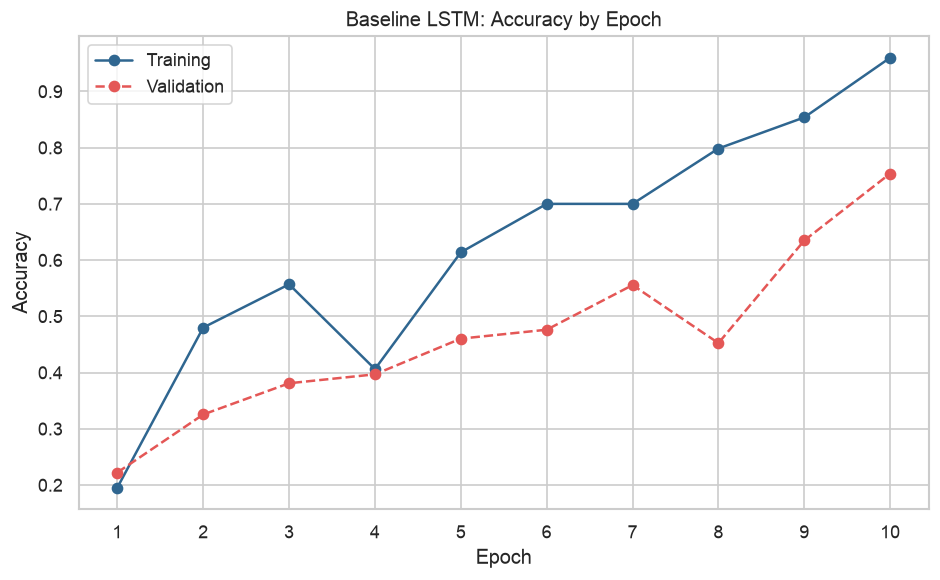

In [40]:
plot_training_metric(baseline_history, "Baseline LSTM", "accuracy", "#2F6690")

### Baseline Loss Curve

The loss graph was examined separately to identify divergence between the training and validation data.

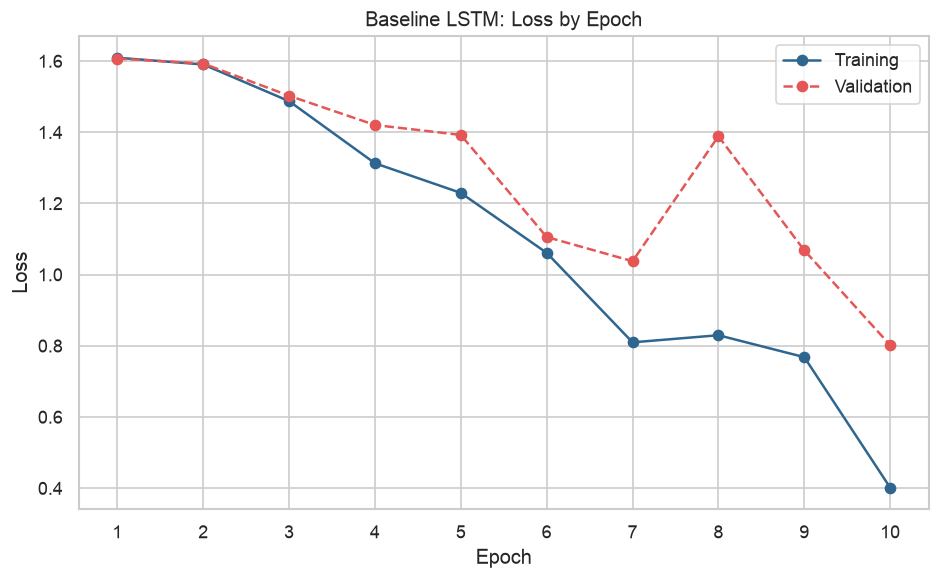

In [41]:
plot_training_metric(baseline_history, "Baseline LSTM", "loss", "#2F6690")

The baseline model's training accuracy increased to 96.00%, while validation accuracy reached 75.40% during the final epoch. The larger difference between training and validation performance indicated some overfitting. Validation loss also fluctuated during training, which supported the need for additional regularisation in the improved model.

## Making Baseline Validation Predictions

I used the baseline LSTM to predict the authors of the validation samples. The validation results were used to compare the models without using the test set during model selection.

In [42]:
baseline_validation_probabilities = baseline_model.predict(X_validation, verbose=0)
baseline_validation_predictions = baseline_validation_probabilities.argmax(axis=1)

## Evaluating the Baseline Model

I evaluated the baseline model on the validation set using accuracy, macro precision, macro recall and macro F1-score. The macro metrics gave each author equal importance when the results were averaged.

In [43]:
def calculate_metrics(model, X_values, y_values, predictions, model_name):
    loss, accuracy = model.evaluate(X_values, y_values, verbose=0)
    precision, recall, f1_score, _ = precision_recall_fscore_support(
        y_values,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Loss": loss,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-Score": f1_score
    }

baseline_validation_metrics = calculate_metrics(
    baseline_model,
    X_validation,
    y_validation,
    baseline_validation_predictions,
    "Baseline LSTM"
)

baseline_validation_table = pd.DataFrame([baseline_validation_metrics])

### Baseline Validation Performance

The validation metrics summarised the baseline model's performance before model improvement and comparison.

In [44]:
display_table(
    baseline_validation_table,
    "Baseline Validation Performance",
    {
        "Loss": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1-Score": "{:.4f}"
    }
)

Model,Loss,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
Baseline LSTM,0.8018,0.7540,0.7643,0.7536,0.7539


## Model Improvement

I improved the model by using a bidirectional LSTM, which processed each sequence in both directions. I also added dropout and L2 regularisation to reduce overfitting, together with early stopping and learning-rate reduction.

In [45]:
keras.backend.clear_session()

improved_model = keras.Sequential([
    layers.Input(shape=(SEQUENCE_LENGTH,)),
    layers.Embedding(
        input_dim=actual_vocabulary_size,
        output_dim=96,
        mask_zero=True
    ),
    layers.SpatialDropout1D(0.25),
    layers.Bidirectional(
        layers.LSTM(64, dropout=0.25, recurrent_dropout=0.15)
    ),
    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.0001)
    ),
    layers.Dropout(0.35),
    layers.Dense(number_of_classes, activation="softmax")
])

improved_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0007),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Improved Model Architecture

The architecture summary showed the additional bidirectional and regularisation components used in the improved model.

In [46]:
improved_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 180, 96)        │       788,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 180, 96)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        82,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 879,269 (3.35 MB)

 Trainable params: 879,269 (3.35 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
improved_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )
]

improved_history = improved_model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=15,
    batch_size=64,
    callbacks=improved_callbacks,
    verbose=1
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 190ms/step - accuracy: 0.2154 - loss: 1.6177 - val_accuracy: 0.2063 - val_loss: 1.6165 - learning_rate: 7.0000e-04
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - accuracy: 0.3046 - loss: 1.6100 - val_accuracy: 0.2460 - val_loss: 1.6137 - learning_rate: 7.0000e-04
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.4400 - loss: 1.5974 - val_accuracy: 0.3016 - val_loss: 1.6058 - learning_rate: 7.0000e-04
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - accuracy: 0.4877 - loss: 1.5688 - val_accuracy: 0.4683 - val_loss: 1.5683 - learning_rate: 7.0000e-04
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.5277 - loss: 1.3736 - val_accuracy: 0.3492 - val_loss: 1.2700 - learning_rate: 7.0000e-04
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.4969 - loss: 1.2220 - val_accuracy: 0.6508 - val_loss: 1.0439 - learning_rate: 7.0000e-04
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - accuracy: 

## Improved Model Training Results

I plotted the training history of the improved model to compare its learning pattern with the baseline model.

### Improved Model Accuracy Curve

The accuracy graph compared the improved model's training and validation performance across epochs.

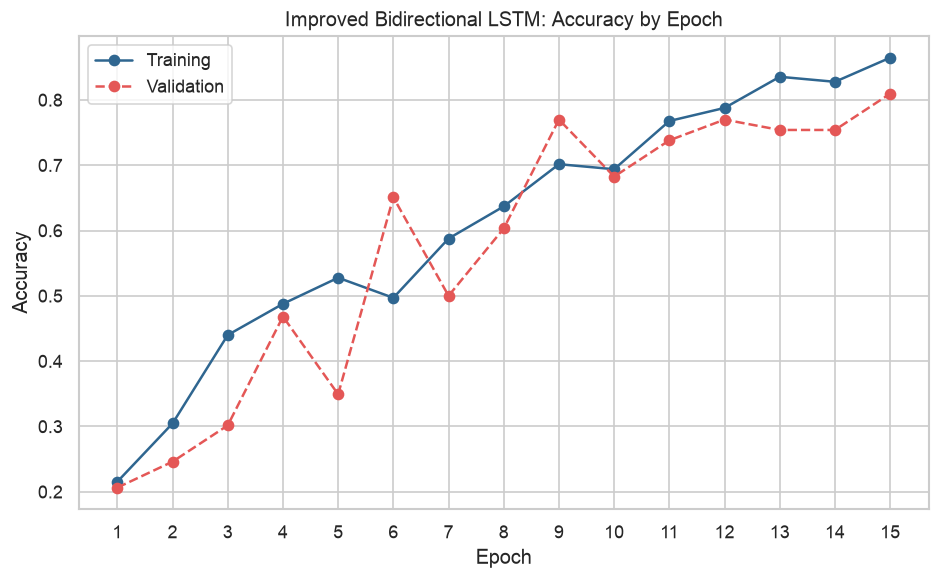

In [48]:
plot_training_metric(improved_history, "Improved Bidirectional LSTM", "accuracy", "#2F6690")

### Improved Model Loss Curve

The separate loss graph showed how regularisation affected generalisation during training.

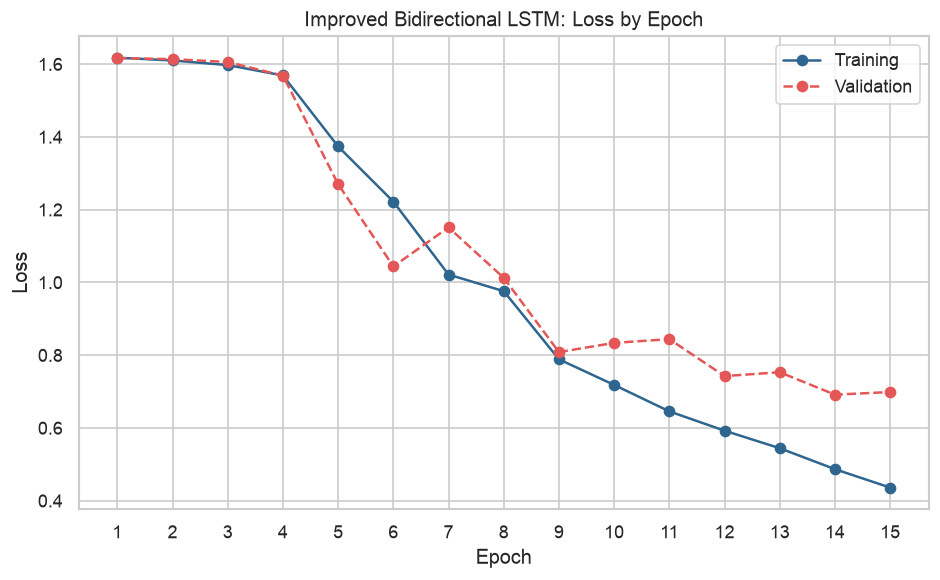

In [49]:
plot_training_metric(improved_history, "Improved Bidirectional LSTM", "loss", "#2F6690")

The improved model's training and validation losses followed a generally downward pattern. The regularisation techniques reduced the large training-validation gap observed in the baseline model, but the final choice was based on the validation macro F1-score rather than the appearance of the training curves alone.

## Comparing the Models

I compared both models using the validation set. The model with the highest validation macro F1-score was selected as the final model because this metric balanced precision and recall across all author classes. The test set was kept separate and was only used after the final model had been selected.

In [50]:
improved_validation_probabilities = improved_model.predict(X_validation, verbose=0)
improved_validation_predictions = improved_validation_probabilities.argmax(axis=1)

improved_validation_metrics = calculate_metrics(
    improved_model,
    X_validation,
    y_validation,
    improved_validation_predictions,
    "Improved Bidirectional LSTM"
)

validation_comparison = pd.DataFrame([
    baseline_validation_metrics,
    improved_validation_metrics
]).set_index("Model")

In [51]:
display_table(
    validation_comparison.reset_index(),
    "Validation Performance Comparison",
    {
        "Loss": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1-Score": "{:.4f}"
    }
)

Model,Loss,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
Baseline LSTM,0.8018,0.7540,0.7643,0.7536,0.7539
Improved Bidirectional LSTM,0.6915,0.7540,0.7700,0.7534,0.7516


In [52]:
best_model_name = validation_comparison["Macro F1-Score"].idxmax()

if best_model_name == "Improved Bidirectional LSTM":
    final_model = improved_model
else:
    final_model = baseline_model

print("Model selected using validation macro F1-score:", best_model_name)

Model selected using validation macro F1-score: Baseline LSTM


The baseline LSTM achieved a validation macro F1-score of 75.39%, compared with 75.16% for the improved bidirectional LSTM. Although the improved model produced a lower validation loss, its macro F1-score was slightly lower. The baseline LSTM was therefore selected without using the test data.

## Final Test Evaluation

After selecting the final model using validation performance, I evaluated it once on the unseen test set. This provided an unbiased measurement of how well the selected model generalised to writing samples that were not used during training or model selection.

In [53]:
final_test_probabilities = final_model.predict(X_test, verbose=0)
final_predictions = final_test_probabilities.argmax(axis=1)

final_test_metrics = calculate_metrics(
    final_model,
    X_test,
    y_test,
    final_predictions,
    best_model_name
)

final_test_table = pd.DataFrame([final_test_metrics])

In [54]:
display_table(
    final_test_table,
    "Final Test Performance",
    {
        "Loss": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1-Score": "{:.4f}"
    }
)

Model,Loss,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
Baseline LSTM,0.8605,0.6935,0.7223,0.6923,0.6971


The selected baseline LSTM achieved a test accuracy of 69.35% and a macro F1-score of 69.71%. This was lower than its validation result, showing that performance varied across unseen source documents. The result nevertheless remained substantially higher than the 20% accuracy expected from random guessing across five balanced author classes.

## Classification Report

I used the classification report to examine precision, recall and F1-score for each author separately.

In [55]:
author_report = classification_report(
    y_test,
    final_predictions,
    labels=np.arange(number_of_classes),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

classification_table = (
    pd.DataFrame(author_report).T
    .reset_index()
    .rename(columns={"index": "Author / Average"})
)

In [56]:
display_table(
    classification_table,
    "Classification Report for the Final Model",
    {
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    }
)

Author / Average,precision,recall,f1-score,support
1265193,0.7200,0.7200,0.7200,25
131294,0.5405,0.8000,0.6452,25
443979,0.5652,0.5417,0.5532,24
5419510,0.9524,0.8000,0.8696,25
5609007,0.8333,0.6000,0.6977,25
accuracy,0.6935,0.6935,0.6935,1
macro avg,0.7223,0.6923,0.6971,124
weighted avg,0.7236,0.6935,0.6983,124


## Confusion Matrix

I used a confusion matrix to identify which authors were predicted correctly and which authors were confused by the final model.

In [57]:
matrix = confusion_matrix(
    y_test,
    final_predictions,
    labels=np.arange(number_of_classes)
)

normalised_matrix = confusion_matrix(
    y_test,
    final_predictions,
    labels=np.arange(number_of_classes),
    normalize="true"
)

### Confusion Matrix - Prediction Counts

The count-based matrix showed the number of correct and incorrect predictions for each author.

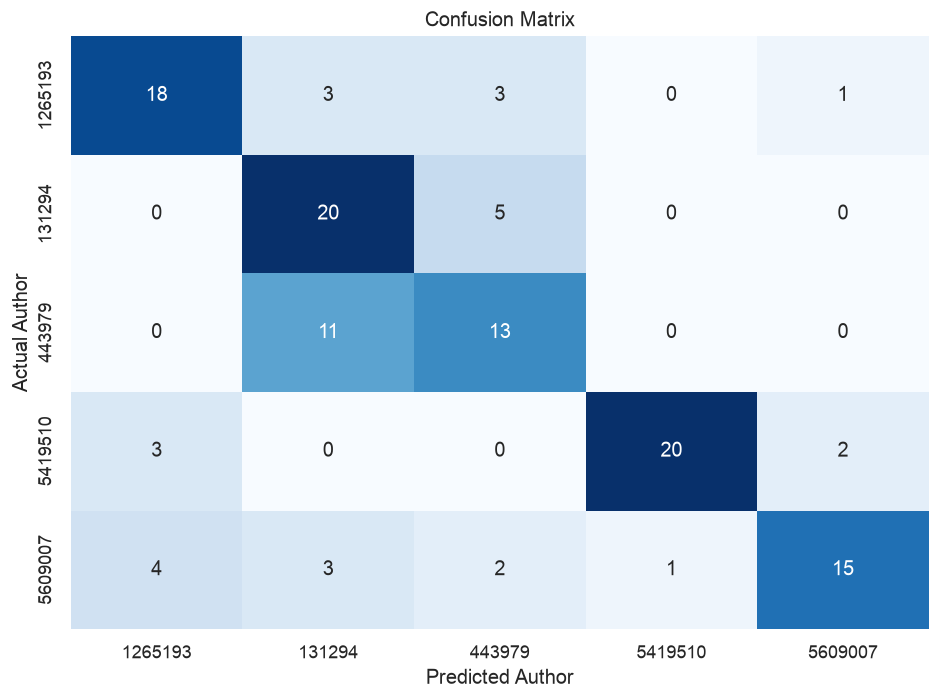

In [58]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Author")
plt.ylabel("Actual Author")
plt.tight_layout()
plt.show()

### Normalised Confusion Matrix

The normalised matrix displayed each author's recall proportion, allowing the five classes to be compared consistently.

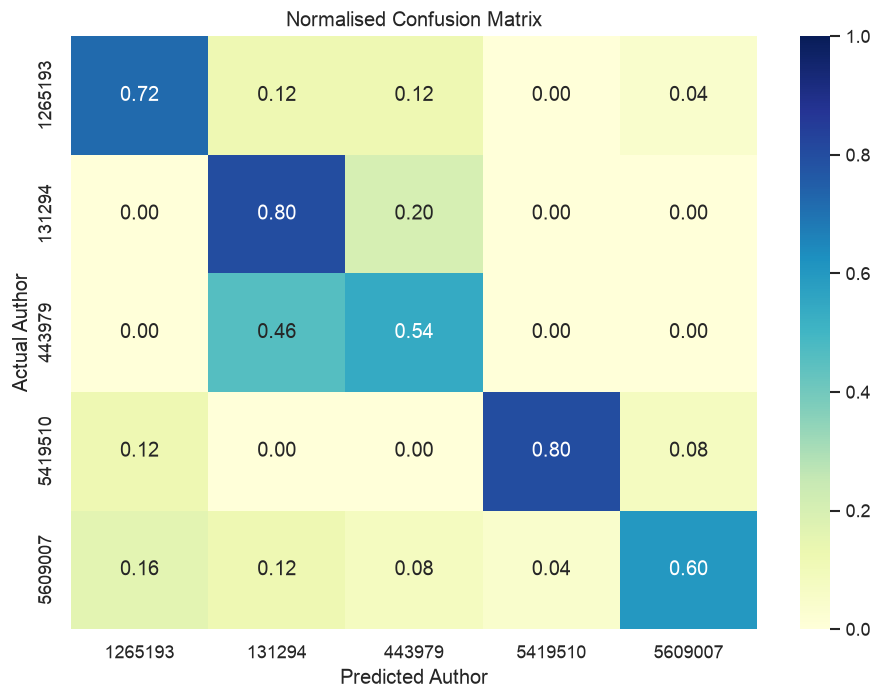

In [59]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    normalised_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Normalised Confusion Matrix")
plt.xlabel("Predicted Author")
plt.ylabel("Actual Author")
plt.tight_layout()
plt.show()

The confusion matrix showed that authors 131294 and 5419510 achieved the strongest recall at 80%. Author 443979 achieved the lowest recall at 54.17% and was most frequently confused with author 131294. Authors 1265193 and 5609007 achieved recall values of 72% and 60% respectively. These differences showed that some authors have more distinctive learned writing patterns than others.

## Testing the Author Identification Bot

I created a function that accepted a writing sample and returned the authors with the highest predicted probabilities. I first tested the bot using a writing sample from the unseen test set.

In [60]:
def predict_author(writing_sample, top_results=3):
    prepared_text = clean_text(writing_sample)
    sequence = tokenizer.texts_to_sequences([prepared_text])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=SEQUENCE_LENGTH,
        padding="post",
        truncating="post"
    )

    probabilities = final_model.predict(padded_sequence, verbose=0)[0]
    top_labels = np.argsort(probabilities)[::-1][:top_results]

    return pd.DataFrame({
        "Author": label_encoder.inverse_transform(top_labels),
        "Probability": probabilities[top_labels]
    })

test_sample = test_data.iloc[0]

print("Actual author:", test_sample["author"])
bot_results = predict_author(test_sample["text"])

Actual author: 1265193


In [61]:
display_table(
    bot_results,
    "Author Identification Bot - Top Predictions",
    {"Probability": "{:.2%}"}
)

Author,Probability
1265193,48.34%
5419510,15.94%
131294,13.70%


## Saving the Final Model

The final model, tokenizer, author labels and model results were saved so that the author identification bot could be reused without training the model again.

In [62]:
OUTPUT_FOLDER = Path("pdan8412_model_output")
OUTPUT_FOLDER.mkdir(exist_ok=True)

final_model.save(OUTPUT_FOLDER / "author_identification_model.keras")

with (OUTPUT_FOLDER / "tokenizer.json").open("w", encoding="utf-8") as file:
    file.write(tokenizer.to_json())

with (OUTPUT_FOLDER / "author_labels.json").open("w", encoding="utf-8") as file:
    json.dump(
        {int(label): author for label, author in enumerate(label_encoder.classes_)},
        file,
        indent=2
    )

validation_comparison.to_csv(OUTPUT_FOLDER / "validation_model_comparison.csv")
pd.DataFrame([final_test_metrics]).to_csv(
    OUTPUT_FOLDER / "final_test_results.csv",
    index=False
)

print("Model files saved in:", OUTPUT_FOLDER.resolve())

Model files saved in: /Users/boitumelomalinga/Documents/PDAN8412_Part1/pdan8412_model_output


## Closing the Spark Session

The Spark session was stopped after the analysis had been completed, releasing the system resources used during processing.

In [63]:
spark.stop()
print("Spark session stopped successfully.")

Spark session stopped successfully.
